# Superdense Coding

Alice wants to send Bob two classical bits, but she can only send him one qubit. A single qubit can normally carry just one bit, but if Alice and Bob already share an entangled pair, Alice can send her half and Bob can read both bits from it.

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()
messages = ["00", "01", "10", "11"]

### The circuit
Alice and Bob start with an entangled pair, where qubit [0] is Alice's and qubit [1] is Bob's. Alice then applies X to her qubit if the second bit is 1 and Z if the first bit is 1, to encode her message, then sends her qubit to Bob. Bob decodes by applying a CNOT and an H, then measures both qubits.

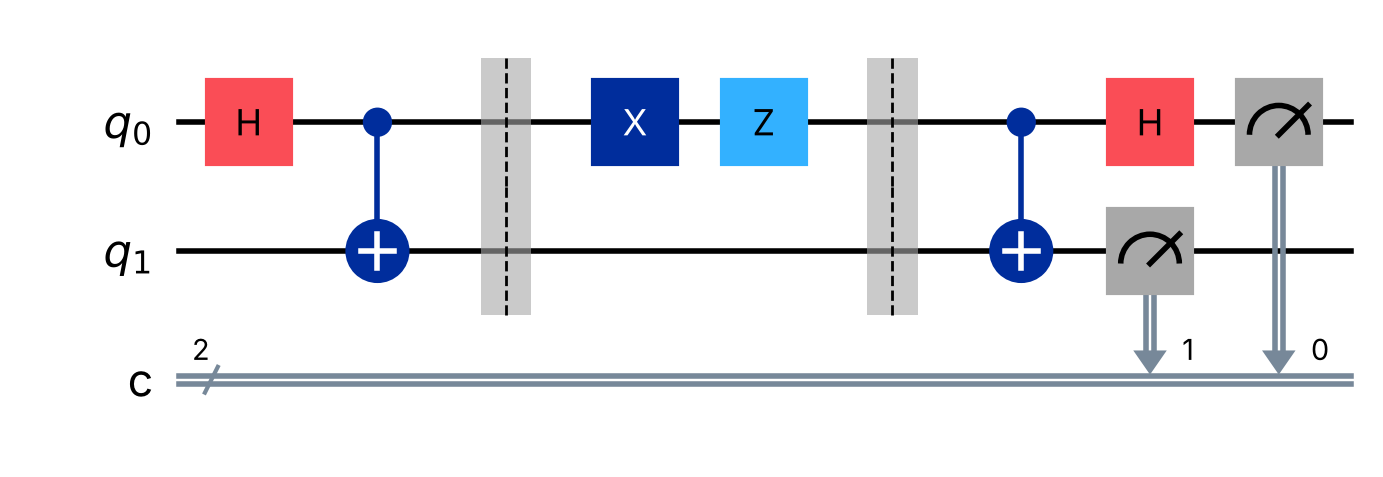

In [3]:
def superdense(message):
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()

    if message[1] == "1":
        qc.x(0)
    if message[0] == "1":
        qc.z(0)
    qc.barrier()

    qc.cx(0, 1)
    qc.h(0)
    qc.measure(0, 0)
    qc.measure(1, 1)
    return qc

superdense("11").draw("mpl")

### Sending all four messages
Each message is sent 1,000 times. Qiskit lists bits with qubit 0 on the right, so we reverse the results to read in the same order as the message.

In [4]:
def send(qc, shots=1000):
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    return {key[::-1]: n for key, n in counts.items()}

received = {m: send(superdense(m)) for m in messages}

for m in messages:
    print(f"sent {m}, received {received[m]}")

sent 00, received {'00': 1000}
sent 01, received {'01': 1000}
sent 10, received {'10': 1000}
sent 11, received {'11': 1000}


### What Eve sees
Suppose Eve intercepts Alice's qubit on its way to Bob and measures it, but without Bob's half of the pair she has no way to decode it.

In [5]:
def eve_peeks(message):
    qc = QuantumCircuit(2, 1)
    qc.h(0)
    qc.cx(0, 1)
    if message[1] == "1":
        qc.x(0)
    if message[0] == "1":
        qc.z(0)
    qc.measure(0, 0)
    return qc

eve_sees = {m: send(eve_peeks(m)) for m in messages}

for m in messages:
    print(f"message {m}, eve measures {eve_sees[m]}")

message 00, eve measures {'0': 496, '1': 504}
message 01, eve measures {'1': 471, '0': 529}
message 10, eve measures {'0': 524, '1': 476}
message 11, eve measures {'1': 506, '0': 494}


no matter the message, eve only has one half, so she gets nothing.

### Results

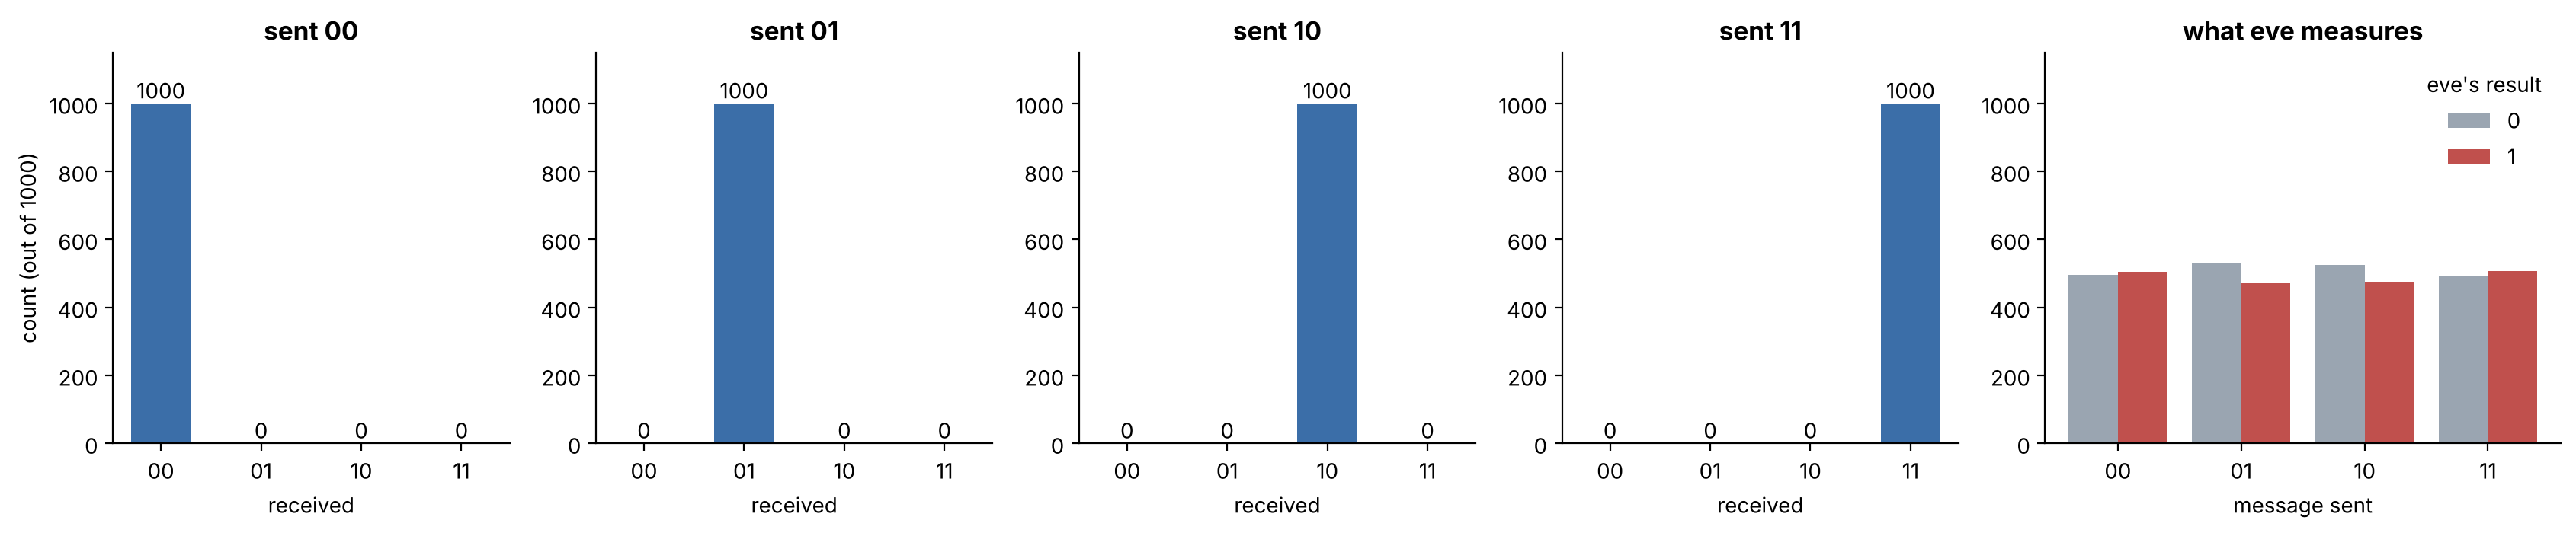

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.3]})

for ax, m in zip(axes[:4], messages):
    counts = [received[m].get(o, 0) for o in messages]
    bars = ax.bar(messages, counts, color="#3b6ea8", width=0.6)
    ax.bar_label(bars, fontsize=10)
    ax.set_ylim(0, 1150)
    ax.set_title(f"sent {m}", fontsize=12, fontweight="bold")
    ax.set_xlabel("received")
axes[0].set_ylabel("count (out of 1000)")

eve_ax = axes[4]
zeros = [eve_sees[m].get("0", 0) for m in messages]
ones = [eve_sees[m].get("1", 0) for m in messages]
x = range(len(messages))
eve_ax.bar([i - 0.2 for i in x], zeros, width=0.4, label="0", color="#9aa5b1")
eve_ax.bar([i + 0.2 for i in x], ones, width=0.4, label="1", color="#c0504d")
eve_ax.set_xticks(list(x), messages)
eve_ax.set_ylim(0, 1150)
eve_ax.set_xlabel("message sent")
eve_ax.set_title("what eve measures", fontsize=12, fontweight="bold")
eve_ax.legend(frameon=False, title="eve's result")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Notes
- Superdense coding is the mirror of teleportation. Teleportation uses an entangled pair and two classical bits to move one qubit's state, while superdense coding uses an entangled pair and one qubit to send two classical bits.
- The entangled pair has to be shared in advance, so the total cost is still two qubits for two bits. The advantage is that one of them can be sent ahead of time, before the message is known.
- Eve can stop the message from reaching Bob by keeping the qubit, but she can't read it.